In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


PROJECT_ROOT = Path.cwd().parent

MODELING_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "modeling"
)

MODEL_DIR = PROJECT_ROOT / "models"

REPRESENTATIONS_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "representations"
)

REPRESENTATIONS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [2]:
X_test_sparse = joblib.load(
    MODELING_DATA_DIR
    / "X_test_target_diag.joblib"
)

y_test = joblib.load(
    MODELING_DATA_DIR
    / "y_test.joblib"
)

print("X_test shape:", X_test_sparse.shape)
print("y_test shape:", y_test.shape)

X_test shape: (19868, 168)
y_test shape: (19868,)


Cilj je izdvojiti reprezentacije koje optimizovani MLP model formira za primere iz test skupa. <br>
Izdvajaju se reprezentacije:<br>
ulaznih podataka.<br>
prvog skrivenog sloja.<br>
drugog skrivenog sloja.<br>
bottleneck sloja.<br>
izlazni logit.

Podatke pretvaramo u tenzore.

In [3]:
X_test_tensor = torch.tensor(
    X_test_sparse.toarray(),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    np.asarray(y_test),
    dtype=torch.float32
).view(-1, 1)

print("X_test tensor:", X_test_tensor.shape)
print("y_test tensor:", y_test_tensor.shape)

X_test tensor: torch.Size([19868, 168])
y_test tensor: torch.Size([19868, 1])


Svaki od 19868 redova predstavlja jednog pacijenta (jedan zapis, primer, mozemo imati vise redova koji predstavljaju istog pacijenta sa vise hospitalizacija) dok 168 kolona predstavlja pretprocesirane ulazne karakteristike.

Definisemo potpuno istu MLP arhitekturu.

In [4]:
class MLP(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dims,
        bottleneck_dim,
        dropout=0.0
    ):
        super().__init__()

        self.fc1 = nn.Linear(
            input_dim,
            hidden_dims[0]
        )

        self.fc2 = nn.Linear(
            hidden_dims[0],
            hidden_dims[1]
        )

        self.bottleneck = nn.Linear(
            hidden_dims[1],
            bottleneck_dim
        )

        self.output = nn.Linear(
            bottleneck_dim,
            1
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        x,
        return_representations=False
    ):
        input_representation = x

        hidden_1 = self.relu(
            self.fc1(x)
        )
        hidden_1 = self.dropout(hidden_1)

        hidden_2 = self.relu(
            self.fc2(hidden_1)
        )
        hidden_2 = self.dropout(hidden_2)

        bottleneck_representation = self.relu(
            self.bottleneck(hidden_2)
        )

        logits = self.output(
            bottleneck_representation
        )

        if return_representations:
            representations = {
                "input": input_representation,
                "hidden_1": hidden_1,
                "hidden_2": hidden_2,
                "bottleneck": bottleneck_representation
            }

            return logits, representations

        return logits

Ucitavanje optimizovanog modela.

In [5]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = MLP(
    input_dim=168,
    hidden_dims=[256, 128],
    bottleneck_dim=16,
    dropout=0.0
).to(device)

model.load_state_dict(
    torch.load(
        MODEL_DIR / "optimized_mlp_model.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print(model)
print("Device:", device)

MLP(
  (fc1): Linear(in_features=168, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bottleneck): Linear(in_features=128, out_features=16, bias=True)
  (output): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
)
Device: cuda


Spajanje ulaza i ciljne vrednosti po indeksu i podela na batch-eve.<br>
prvi batch: primeri od 0-127, <br>
drugi batch: primeri od 128-255 itd. <br>
<br>
kod testiranja koristimo shuffle: false da bi redosled primera bio stabilan, kod treniranja, model u svakoj epohi vidi primere razlicitim redom sto sprecava da se model prilagodi redosledu podataka.<br>
<br>
kod testiranja, zelimo da se svaki red u svakom sloju odnosi na isti primer iz test skupa (npr red 0 ulazni sloj = red 0 prvi skriveni =....). <br>
vazno nam je zbog poredjenja matrica, slojeva, povezanosti bottleneck sloja sa ulaznim karakteristikama, CKA, RSA itd..

In [6]:
test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

representation_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

Funkcija za izdvajanje reprezentacija.<br>
Cilj funkcije je da provuce test skup kroz optimizovani MLP model i sacuva sta je svaki sloj proizveo za svaki primer. <br>
Pored unutrasnjih reprezentacija cuvamo i logit - sirovi izlaz pre sigmoid funkcije, collected_probabilities - sigmoid transformaciju logit-a (verovatnoca pozitivne klase) i collected_labels - stvarne oznake iz test skupa (radi poredjenja). <br>
model prebacujemo u rezim evaluacije (dropout se iskljucuje jer se koristi iskljucivo prilikom treniranja). <br>
iskljucujemo racunanje gradijenta jer ne treniramo model i ne menjamo tezine (brza obrada i smanjena potrosnja memorije).<br>
svaki batch prolazi kroz model i vraca logit i batch_representations jer u nasoj forward metodi postoji return_representations, te ovako dobijamo sve reprezentacije istog primera kroz mrezu. <br>
Reprezentacije pretvaramo u verovatnoce i sve "pakujemo" u listu batch matrica i concatenate spaja po redovima da bismo konacno dobili jednu numpy matricu za svaki sloj.<br>
<br>
collected_representations je recnik koji sadrzi 4 velike matrice za svaki sloj.

In [7]:
def extract_representations(
    model,
    data_loader,
    device
):
    collected_representations = {
        "input": [],
        "hidden_1": [],
        "hidden_2": [],
        "bottleneck": []
    }

    collected_logits = []
    collected_probabilities = []
    collected_labels = []

    model.eval()

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)

            logits, batch_representations = model(
                X_batch,
                return_representations=True
            )

            probabilities = torch.sigmoid(logits)

            for layer_name, values in (
                batch_representations.items()
            ):
                collected_representations[
                    layer_name
                ].append(
                    values.cpu().numpy()
                )

            collected_logits.append(
                logits.cpu().numpy()
            )

            collected_probabilities.append(
                probabilities.cpu().numpy()
            )

            collected_labels.append(
                y_batch.numpy()
            )

    for layer_name in collected_representations:
        collected_representations[layer_name] = (
            np.concatenate(
                collected_representations[layer_name],
                axis=0
            )
        )

    collected_logits = np.concatenate(
        collected_logits,
        axis=0
    )

    collected_probabilities = np.concatenate(
        collected_probabilities,
        axis=0
    )

    collected_labels = np.concatenate(
        collected_labels,
        axis=0
    )

    return (
        collected_representations,
        collected_logits,
        collected_probabilities,
        collected_labels
    )

Pozivanje funkcije.

In [8]:
(
    representations,
    test_logits,
    test_probabilities,
    test_labels
) = extract_representations(
    model=model,
    data_loader=representation_loader,
    device=device
)

Provera dimenzija.

In [9]:
for layer_name, values in representations.items():
    print(
        f"{layer_name}: {values.shape}"
    )

print("logits:", test_logits.shape)
print(
    "probabilities:",
    test_probabilities.shape
)
print("labels:", test_labels.shape)

input: (19868, 168)
hidden_1: (19868, 256)
hidden_2: (19868, 128)
bottleneck: (19868, 16)
logits: (19868, 1)
probabilities: (19868, 1)
labels: (19868, 1)


In [10]:
np.savez_compressed(
    REPRESENTATIONS_DIR
    / "optimized_mlp_test_representations.npz",

    input=representations["input"],
    hidden_1=representations["hidden_1"],
    hidden_2=representations["hidden_2"],
    bottleneck=representations["bottleneck"],
    logits=test_logits,
    probabilities=test_probabilities,
    labels=test_labels
)

print("Representations saved successfully.")

Representations saved successfully.


Mozemo videti raspodelu verovatnoca.

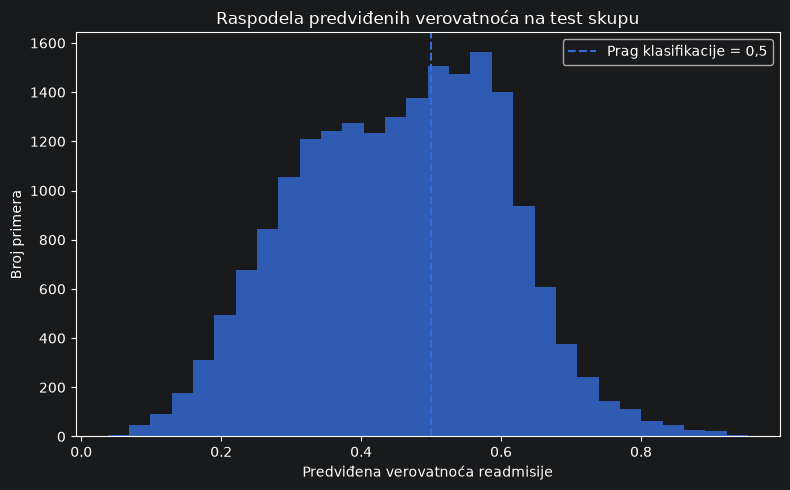

In [11]:
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURES_DIR
    / "predicted_probabilities_distribution.png"
)

plt.figure(figsize=(8, 5))

plt.hist(
    test_probabilities[:, 0],
    bins=30,
    alpha=0.8
)

plt.axvline(
    x=0.5,
    linestyle="--",
    label="Prag klasifikacije = 0,5"
)

plt.xlabel("Predviđena verovatnoća readmisije")
plt.ylabel("Broj primera")
plt.title(
    "Raspodela predviđenih verovatnoća na test skupu"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Raspodela verovatnoca pokazuje da se najveci broj predikcija nalazi u intervalu od 0.2 do 0.7, sa najvecom koncentracijom oko vrednosti 0.5, 0.6.<br>
Mali broj primera dobija veoma niske ili veoma visoke verovatnoce, sto ukazuje da model retko donosi izrazito sigurne predikcije.<br>
Veliki broj vrednosti oko praga odlucivanja govori da model nije potpuno siguran kojoj klasi pripadaju, ipak, samo na osnovu histograma nije moguce zakljuciti da li su predikcije tacne, vec samo kako su rasporedjene verovatnoce.

Raspodela aktivacija po slojevima.

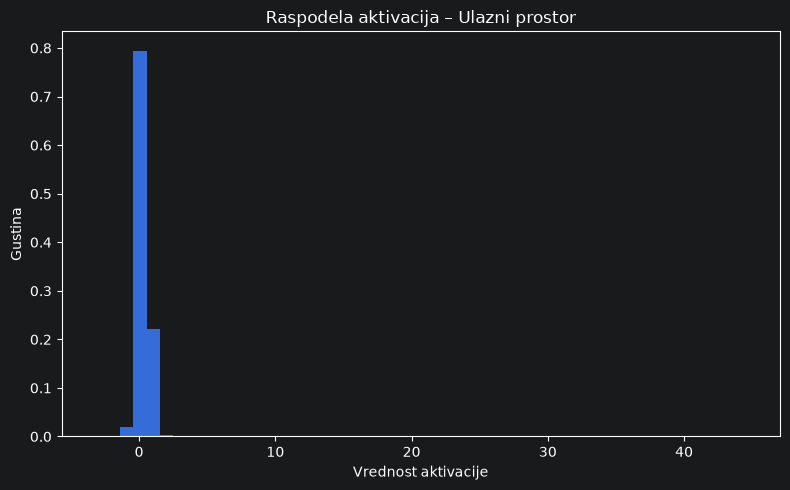

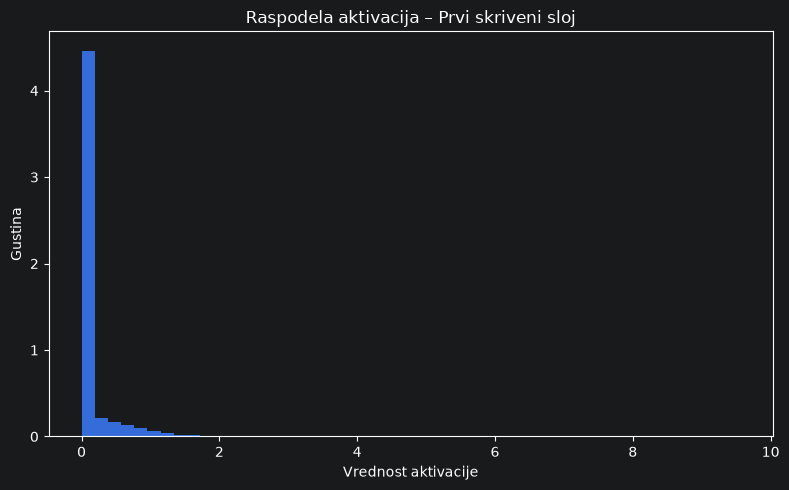

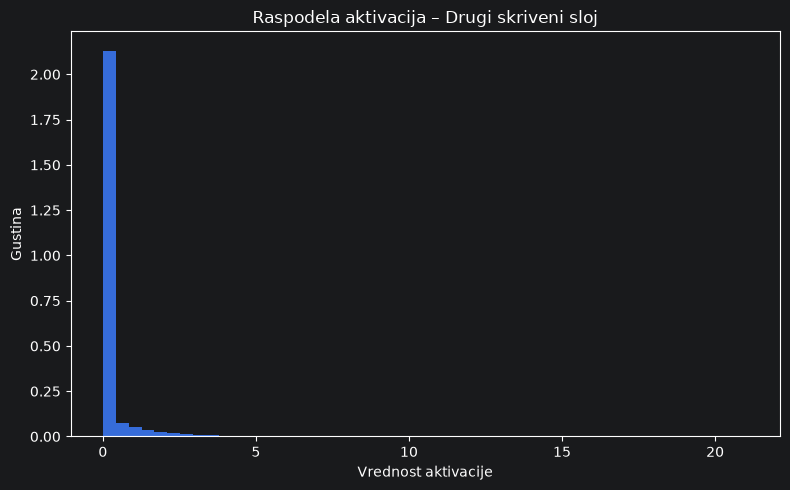

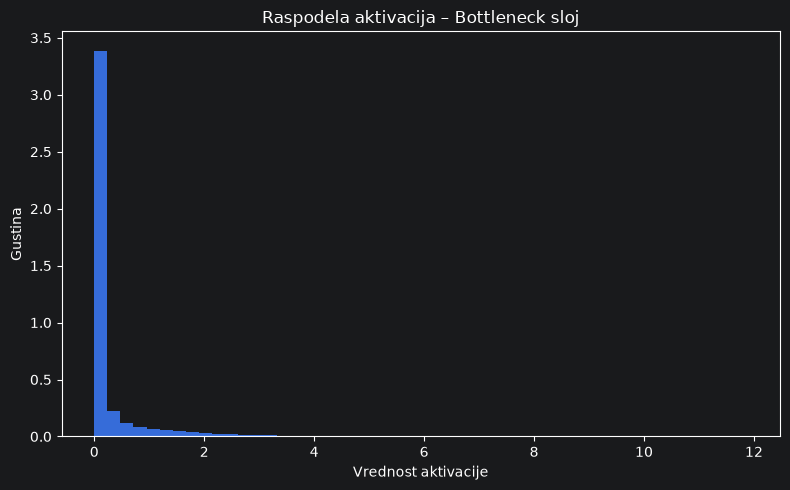

In [12]:
import matplotlib.pyplot as plt


layer_names = [
    "input",
    "hidden_1",
    "hidden_2",
    "bottleneck"
]

layer_titles = {
    "input": "Ulazni prostor",
    "hidden_1": "Prvi skriveni sloj",
    "hidden_2": "Drugi skriveni sloj",
    "bottleneck": "Bottleneck sloj"
}


for layer_name in layer_names:

    activation_values = (
        representations[layer_name]
        .ravel()
    )

    figure_path = (
        FIGURES_DIR
        / f"{layer_name}_activation_distribution.png"
    )

    plt.figure(figsize=(8, 5))

    plt.hist(
        activation_values,
        bins=50,
        density=True
    )

    plt.xlabel("Vrednost aktivacije")
    plt.ylabel("Gustina")
    plt.title(
        f"Raspodela aktivacija – "
        f"{layer_titles[layer_name]}"
    )

    plt.tight_layout()

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Mozemo uociti veliku koncentraciju vrednosti oko nule i dugacak rep pozitivnih vrednosti, sto je ocekivano jer posle svakog linearnog sloja koristimo ReLU funkciju koja sve negativne vrednosti pretvara u nulu.<br>
Samo deo neurona ima izrazene aktivacije. <br>
Velika koncentracija oko nule je ocekivana i zbog velikoj broja enkodovanih kategorickih karakteristika, kod one-hot encoding-a vecina vrednosti je 0 a samo mali broj ima vrednost 1 za odredjeni primer.<br>
Potrebno je proveriti da li imamo neurone koji su uvek mrtvi.<br>
Mrtav neuron je onaj koji daje nulu za sve primere, takav neuron ne prenosi korisnu informaciju.

Zato posmatramo sledecu analizu.

In [13]:
activation_summary = []

for layer_name in ["hidden_1", "hidden_2", "bottleneck"]:
    values = representations[layer_name]

    activation_summary.append({
        "layer": layer_name,
        "shape": values.shape,
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "max": values.max(),
        "zero_fraction": np.mean(values == 0),
        "dead_neurons": np.sum(
            np.all(values == 0, axis=0)
        )
    })

activation_summary_df = pd.DataFrame(
    activation_summary
)

activation_summary_df

,layer,shape,mean,std,min,max,zero_fraction,dead_neurons
0,hidden_1,"(19868, 256)",0.103054,0.282711,0.0,9.556805,0.802994,35
1,hidden_2,"(19868, 128)",0.169949,0.588764,0.0,21.065958,0.851455,60
2,bottleneck,"(19868, 16)",0.260744,0.733062,0.0,11.879476,0.732714,5


Dakle ne koristi se bas svih 16 bottleneck dimenzija, vec 11.<br>
shape: dimenzija matrice aktivacija sloja.<br>
mean: prosecna vrednost svih aktivacija u matrici sloja.<br>
std: standardna devijacija aktivacija.<br>
min: najmanja aktivaciona vrednost.<br>
max: najveca aktivaciona vrednost.<br>
zero_fraction: udeo svih aktivacionih vrednosti koje su jednake 0, u sustini, koliko je pojedinacnih celija u matrici jednako 0.<br>
dead_neurons: broj neurona koji su imali aktivaciju 0 za svih 19868 primera.